In [1]:
from google.colab import files

uploaded = files.upload()

Saving Marketing_Campaign_Data.xlsx to Marketing_Campaign_Data.xlsx


In [2]:
# Step 2: Load the Excel workbook

file_name = next(iter(uploaded.keys()))

# Read all three sheets
campaign_df = pd.read_excel(
    file_name, sheet_name="CampaignPerformance"
)

meta_df = pd.read_excel(
    file_name, sheet_name="CampaignMeta"
)

rates_df = pd.read_excel(
    file_name, sheet_name="ChannelRates"
)

print("DATASET LOADED SUCCESSFULLY!")

# Check available sheets
print("\nAvailable sheets:")
print(pd.ExcelFile(file_name).sheet_names)

# Check main dataset size
print("\nDataset Shape:")
print(campaign_df.shape)

# Check column names
print("\nColumn Names:")
print(campaign_df.columns.tolist())

# Display first 5 rows
print("\nFirst 5 Records:")
display(campaign_df.head())

# Dataset information
print("\nDataset Information:")
campaign_df.info()

# Check missing values
print("\nMissing Values:")
print(campaign_df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:")
print(campaign_df.duplicated().sum())

NameError: name 'pd' is not defined

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# Step 2: Load the Excel workbook

file_name = next(iter(uploaded.keys()))

campaign_df = pd.read_excel(
    file_name, sheet_name="CampaignPerformance"
)

In [6]:
# STEP 3: DATA CLEANING

# Create a copy of the original dataset
campaign_clean = campaign_df.copy()

# 1. Remove extra spaces from text columns
for col in campaign_clean.select_dtypes(include="object").columns:
    campaign_clean[col] = campaign_clean[col].str.strip()

# 2. Convert Date column into proper date format
if pd.api.types.is_numeric_dtype(campaign_clean["Date"]):
    campaign_clean["Date"] = pd.to_datetime(
        campaign_clean["Date"],
        unit="D",
        origin="1899-12-30",
        errors="coerce"
    )
else:
    campaign_clean["Date"] = pd.to_datetime(
        campaign_clean["Date"],
        errors="coerce"
    )

# 3. Convert numeric columns into numeric data types
numeric_columns = [
    "Impressions", "Clicks", "Leads",
    "Applications", "Enrollments",
    "Cost (₹)", "Revenue (₹)"
]

for col in numeric_columns:
    campaign_clean[col] = pd.to_numeric(
        campaign_clean[col], errors="coerce"
    )

# 4. Remove duplicate records
before = len(campaign_clean)
campaign_clean = campaign_clean.drop_duplicates()
removed = before - len(campaign_clean)

# 5. Check missing values
print("DATA CLEANING COMPLETED!")
print("--------------------------------")
print("Original rows:", before)
print("Duplicate rows removed:", removed)
print("Remaining rows:", len(campaign_clean))

print("\nMissing Values After Cleaning:")
print(campaign_clean.isnull().sum())

print("\nCleaned Dataset Preview:")
display(campaign_clean.head())

DATA CLEANING COMPLETED!
--------------------------------
Original rows: 763
Duplicate rows removed: 0
Remaining rows: 763

Missing Values After Cleaning:
Date              0
CampaignID        0
CampaignName      0
Platform          0
TargetAudience    0
Impressions       0
Clicks            0
Leads             0
Applications      0
Enrollments       0
Cost (₹)          0
Revenue (₹)       0
Region            0
dtype: int64

Cleaned Dataset Preview:


,Date,CampaignID,CampaignName,Platform,TargetAudience,Impressions,Clicks,Leads,Applications,Enrollments,Cost (₹),Revenue (₹),Region
0,2024-01-01,AD004,Hackathon,YouTube,17–21 Age,285708,16956,4087,2547,1148,275457.87,4615838.04,West India
1,2024-01-02,AD004,Hackathon,YouTube,17–21 Age,140449,10082,1815,951,565,133025.86,3513169.90,North India
2,2024-01-03,AD004,Hackathon,YouTube,17–21 Age,140958,7474,1169,683,343,135765.61,1051924.88,North India
3,2024-01-04,AD004,Hackathon,YouTube,22–27 Age,257823,16841,3179,1584,698,229715.44,3850639.56,West India
4,2024-01-05,AD004,Hackathon,YouTube,25–35 Age,98595,7293,1340,854,368,52360.96,1543262.86,West India


In [7]:
# STEP 4: MARKETING CHANNEL PERFORMANCE

# Group campaign data by advertising platform
channel_summary = (
    campaign_clean.groupby("Platform", as_index=False)
    .agg({
        "Impressions": "sum",
        "Clicks": "sum",
        "Leads": "sum",
        "Applications": "sum",
        "Enrollments": "sum",
        "Cost (₹)": "sum",
        "Revenue (₹)": "sum"
    })
)

# Calculate marketing performance metrics
channel_summary["CTR (%)"] = (
    channel_summary["Clicks"] /
    channel_summary["Impressions"].replace(0, np.nan) * 100
)

channel_summary["Lead Conversion (%)"] = (
    channel_summary["Leads"] /
    channel_summary["Clicks"].replace(0, np.nan) * 100
)

channel_summary["Enrollment Rate (%)"] = (
    channel_summary["Enrollments"] /
    channel_summary["Applications"].replace(0, np.nan) * 100
)

# Calculate Return on Investment
channel_summary["ROI (%)"] = (
    (channel_summary["Revenue (₹)"] -
     channel_summary["Cost (₹)"]) /
    channel_summary["Cost (₹)"].replace(0, np.nan) * 100
)

# Calculate Return on Ad Spend
channel_summary["ROAS"] = (
    channel_summary["Revenue (₹)"] /
    channel_summary["Cost (₹)"].replace(0, np.nan)
)

# Round numerical results
channel_summary = channel_summary.round(2)

# Display results from highest ROI to lowest
channel_summary = channel_summary.sort_values(
    by="ROI (%)", ascending=False
)

print("MARKETING CHANNEL PERFORMANCE REPORT")
display(channel_summary)

MARKETING CHANNEL PERFORMANCE REPORT


,Platform,Impressions,Clicks,Leads,Applications,Enrollments,Cost (₹),Revenue (₹),CTR (%),Lead Conversion (%),Enrollment Rate (%),ROI (%),ROAS
3,LinkedIn,26146791,1460099,292161,163739,83522,18258974.94,4.646099e+08,5.58,20.01,51.01,2444.56,25.45
2,Instagram,24699279,1347998,270522,148302,75249,17285042.28,4.149747e+08,5.46,20.07,50.74,2300.77,24.01
0,Facebook,31329302,1740443,350452,191054,94199,22051324.43,5.172759e+08,5.56,20.14,49.30,2245.78,23.46
1,Google Ads,31963554,1751859,346441,190327,95402,23158075.68,5.319735e+08,5.48,19.78,50.13,2197.14,22.97
4,YouTube,15019263,838013,161708,90194,43942,10694713.86,2.366285e+08,5.58,19.30,48.72,2112.57,22.13


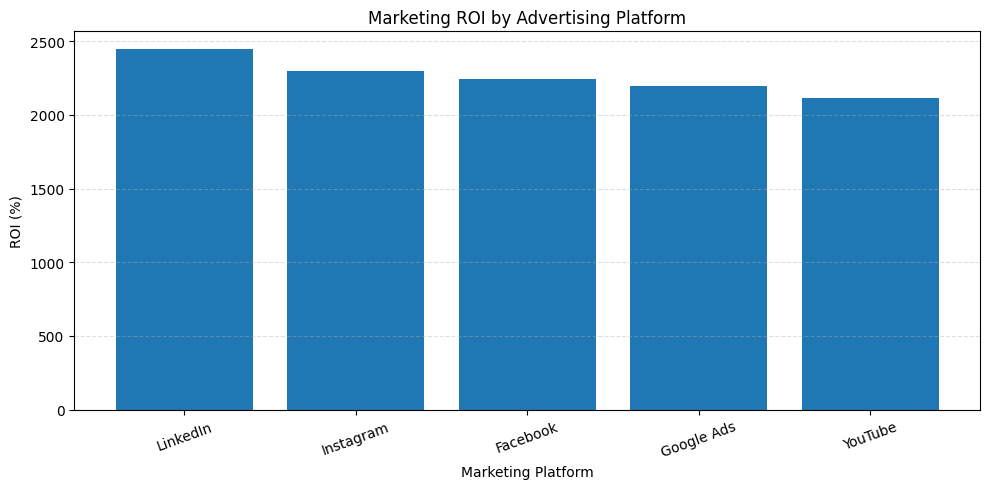

In [8]:
# STEP 5: ROI COMPARISON CHART

plt.figure(figsize=(10, 5))

plt.bar(
    channel_summary["Platform"],
    channel_summary["ROI (%)"]
)

plt.title("Marketing ROI by Advertising Platform")
plt.xlabel("Marketing Platform")
plt.ylabel("ROI (%)")

plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

MARKETING FUNNEL SUMMARY


,Stage,Count,Conversion Rate (%)
0,Impressions,129158189,100.00
1,Clicks,7138412,5.53
2,Leads,1421284,19.91
3,Applications,783616,55.13
4,Enrollments,392314,50.06


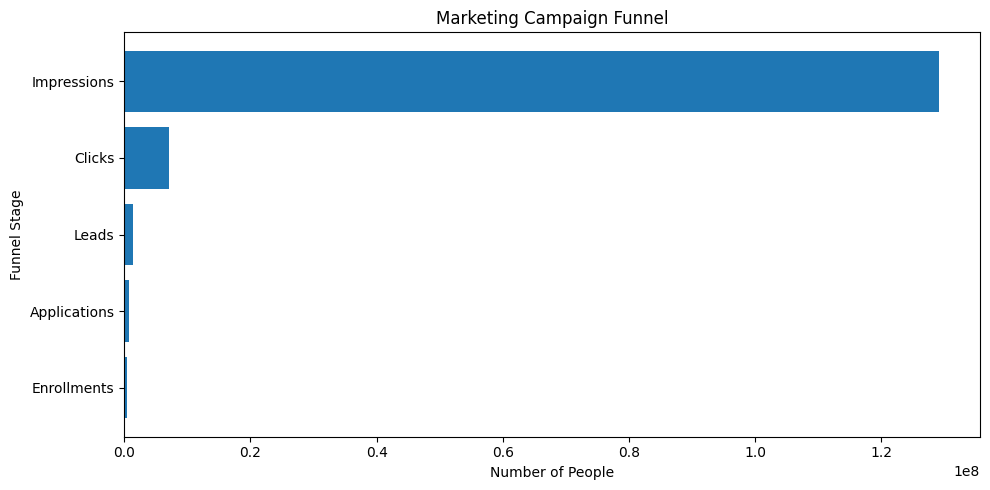

In [9]:
# STEP 6: MARKETING FUNNEL ANALYSIS

stages = [
    "Impressions",
    "Clicks",
    "Leads",
    "Applications",
    "Enrollments"
]

funnel_values = [
    campaign_clean["Impressions"].sum(),
    campaign_clean["Clicks"].sum(),
    campaign_clean["Leads"].sum(),
    campaign_clean["Applications"].sum(),
    campaign_clean["Enrollments"].sum()
]

# Create funnel summary
funnel_df = pd.DataFrame({
    "Stage": stages,
    "Count": funnel_values
})

# Calculate conversion from previous stage
funnel_df["Conversion Rate (%)"] = (
    funnel_df["Count"] /
    funnel_df["Count"].shift(1) * 100
)

funnel_df.loc[0, "Conversion Rate (%)"] = 100

print("MARKETING FUNNEL SUMMARY")
display(funnel_df.round(2))

# Create funnel chart
plt.figure(figsize=(10, 5))

plt.barh(stages, funnel_values)

plt.title("Marketing Campaign Funnel")
plt.xlabel("Number of People")
plt.ylabel("Funnel Stage")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [10]:
# STEP 7: CAMPAIGN DETAILS ANALYSIS

print("CAMPAIGN METADATA")
print("Columns:", meta_df.columns.tolist())
display(meta_df.head(10))

print("\nCHANNEL RATE DETAILS")
print("Columns:", rates_df.columns.tolist())
display(rates_df.head(10))

CAMPAIGN METADATA


NameError: name 'meta_df' is not defined

In [11]:
# FIX: LOAD CAMPAIGN METADATA AND CHANNEL RATES

file_name = "Marketing_Campaign_Data.xlsx"

# Load the remaining sheets
meta_df = pd.read_excel(
    file_name,
    sheet_name="CampaignMeta"
)

rates_df = pd.read_excel(
    file_name,
    sheet_name="ChannelRates"
)

print("CAMPAIGN METADATA")
print("Shape:", meta_df.shape)
print("Columns:", meta_df.columns.tolist())
display(meta_df.head(10))

print("\nCHANNEL RATE DETAILS")
print("Shape:", rates_df.shape)
print("Columns:", rates_df.columns.tolist())
display(rates_df.head(10))

CAMPAIGN METADATA
Shape: (5, 10)
Columns: ['CampaignID', 'Objective', 'StartDate', 'EndDate', 'Budget (₹)', 'Campaign Type', 'Creative Type', 'Manager', 'Channel', 'Conversion Goal']


,CampaignID,Objective,StartDate,EndDate,Budget (₹),Campaign Type,Creative Type,Manager,Channel,Conversion Goal
0,AD001,Lead Generation,2024-03-01,2024-08-31,1800000,Paid Search,Static Ads,Priya,Google Ads,Application
1,AD002,Admissions,2025-05-01,2025-10-31,1500000,Paid Social,Video,Rohit,Facebook,Lead
2,AD003,Career Promotion,2025-01-01,2025-05-31,1000000,Professional Networking,Carousel,Ananya,LinkedIn,Placement
3,AD004,Brand Awareness,2024-01-01,2024-03-31,800000,Event Marketing,Video,Arjun,YouTube,Registration
4,AD005,Student Exchange,2024-08-01,2024-12-31,1200000,Social Media,Reels,Megha,Instagram,Application



CHANNEL RATE DETAILS
Shape: (5, 4)
Columns: ['Channel', 'AvgCPM', 'AvgCPC', 'Remarks']


,Channel,AvgCPM,AvgCPC,Remarks
0,Google Ads,80,12,High search volume
1,Facebook,70,10,Engagement focused
2,LinkedIn,120,20,Professional targeting
3,YouTube,90,15,Video rich
4,Instagram,60,9,Youth appeal


In [12]:
# STEP 7: CAMPAIGN-LEVEL ANALYSIS

# Load campaign details
meta_df = pd.read_excel(
    file_name,
    sheet_name="CampaignMeta"
)

# Summarize campaign performance
campaign_summary = (
    campaign_clean.groupby(
        ["CampaignID", "CampaignName", "Platform"],
        as_index=False
    )
    .agg({
        "Impressions": "sum",
        "Clicks": "sum",
        "Leads": "sum",
        "Applications": "sum",
        "Enrollments": "sum",
        "Cost (₹)": "sum",
        "Revenue (₹)": "sum"
    })
)

# Add campaign objectives and creative details
campaign_summary = campaign_summary.merge(
    meta_df[
        [
            "CampaignID",
            "Objective",
            "Budget (₹)",
            "Campaign Type",
            "Creative Type",
            "Conversion Goal"
        ]
    ],
    on="CampaignID",
    how="left"
)

# Calculate ROI and ROAS
campaign_summary["ROI (%)"] = (
    (campaign_summary["Revenue (₹)"] -
     campaign_summary["Cost (₹)"]) /
    campaign_summary["Cost (₹)"] * 100
)

campaign_summary["ROAS"] = (
    campaign_summary["Revenue (₹)"] /
    campaign_summary["Cost (₹)"]
)

# Display campaign report
campaign_summary = campaign_summary.sort_values(
    "ROI (%)",
    ascending=False
)

print("CAMPAIGN-LEVEL BUSINESS ANALYSIS")

display(campaign_summary.round(2))

CAMPAIGN-LEVEL BUSINESS ANALYSIS


,CampaignID,CampaignName,Platform,Impressions,Clicks,Leads,Applications,Enrollments,Cost (₹),Revenue (₹),Objective,Budget (₹),Campaign Type,Creative Type,Conversion Goal,ROI (%),ROAS
2,AD003,Placements,LinkedIn,26146791,1460099,292161,163739,83522,18258974.94,4.646099e+08,Career Promotion,1000000,Professional Networking,Carousel,Placement,2444.56,25.45
4,AD005,Semester Exchange Program,Instagram,24699279,1347998,270522,148302,75249,17285042.28,4.149747e+08,Student Exchange,1200000,Social Media,Reels,Application,2300.77,24.01
1,AD002,MBA Admission,Facebook,31329302,1740443,350452,191054,94199,22051324.43,5.172759e+08,Admissions,1500000,Paid Social,Video,Lead,2245.78,23.46
0,AD001,UG Admission,Google Ads,31963554,1751859,346441,190327,95402,23158075.68,5.319735e+08,Lead Generation,1800000,Paid Search,Static Ads,Application,2197.14,22.97
3,AD004,Hackathon,YouTube,15019263,838013,161708,90194,43942,10694713.86,2.366285e+08,Brand Awareness,800000,Event Marketing,Video,Registration,2112.57,22.13


CAMPAIGN BUDGET ANALYSIS


,CampaignID,CampaignName,Platform,Cost (₹),Budget (₹),Budget Utilization (%)
0,AD001,UG Admission,Google Ads,23158075.68,1800000,1286.56
1,AD002,MBA Admission,Facebook,22051324.43,1500000,1470.09
2,AD003,Placements,LinkedIn,18258974.94,1000000,1825.90
3,AD004,Hackathon,YouTube,10694713.86,800000,1336.84
4,AD005,Semester Exchange Program,Instagram,17285042.28,1200000,1440.42



ADVERTISING COST COMPARISON


,Platform,Impressions,Clicks,Cost (₹),Actual CPM (₹),Actual CPC (₹),Channel,AvgCPM,AvgCPC,Remarks
0,Facebook,31329302,1740443,22051324.43,703.86,12.67,Facebook,70,10,Engagement focused
1,Google Ads,31963554,1751859,23158075.68,724.52,13.22,Google Ads,80,12,High search volume
2,Instagram,24699279,1347998,17285042.28,699.82,12.82,Instagram,60,9,Youth appeal
3,LinkedIn,26146791,1460099,18258974.94,698.33,12.51,LinkedIn,120,20,Professional targeting
4,YouTube,15019263,838013,10694713.86,712.07,12.76,YouTube,90,15,Video rich


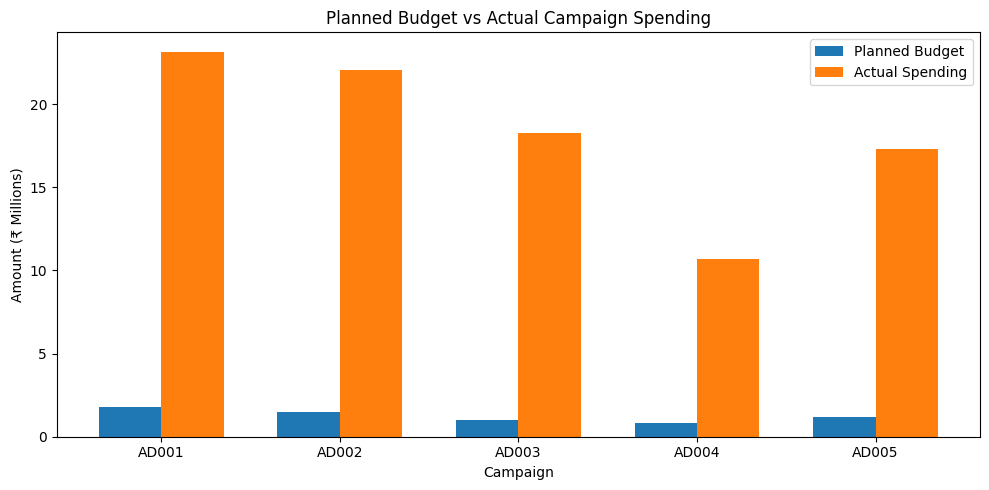

In [13]:
# STEP 8: BUDGET AND COST ANALYSIS

# Calculate total spending for each campaign
campaign_spend = (
    campaign_clean.groupby(
        ["CampaignID", "CampaignName", "Platform"],
        as_index=False
    )
    .agg({"Cost (₹)": "sum"})
)

# Compare actual spending with planned budgets
budget_check = campaign_spend.merge(
    meta_df[["CampaignID", "Budget (₹)"]],
    on="CampaignID",
    how="left"
)

budget_check["Budget Utilization (%)"] = (
    budget_check["Cost (₹)"] /
    budget_check["Budget (₹)"] * 100
)

print("CAMPAIGN BUDGET ANALYSIS")
display(budget_check.round(2))

# Calculate actual advertising costs
cost_analysis = (
    campaign_clean.groupby("Platform", as_index=False)
    .agg({
        "Impressions": "sum",
        "Clicks": "sum",
        "Cost (₹)": "sum"
    })
)

cost_analysis["Actual CPM (₹)"] = (
    cost_analysis["Cost (₹)"] /
    cost_analysis["Impressions"] * 1000
)

cost_analysis["Actual CPC (₹)"] = (
    cost_analysis["Cost (₹)"] /
    cost_analysis["Clicks"]
)

# Compare with reference channel rates
cost_analysis = cost_analysis.merge(
    rates_df,
    left_on="Platform",
    right_on="Channel",
    how="left"
)

print("\nADVERTISING COST COMPARISON")
display(cost_analysis.round(2))

# Create budget comparison chart
plt.figure(figsize=(10, 5))

x = np.arange(len(budget_check))
width = 0.35

plt.bar(
    x - width/2,
    budget_check["Budget (₹)"] / 1000000,
    width,
    label="Planned Budget"
)

plt.bar(
    x + width/2,
    budget_check["Cost (₹)"] / 1000000,
    width,
    label="Actual Spending"
)

plt.xticks(
    x,
    budget_check["CampaignID"]
)

plt.title("Planned Budget vs Actual Campaign Spending")
plt.xlabel("Campaign")
plt.ylabel("Amount (₹ Millions)")
plt.legend()
plt.tight_layout()
plt.show()

REGION-WISE PERFORMANCE


,Region,Impressions,Clicks,Leads,Enrollments,Cost (₹),Revenue (₹),ROI (%),ROAS
0,East India,24592664,1343443,263171,72236,17552873.96,4.074325e+08,2221.17,23.21
1,North India,27575079,1520313,307079,85047,19529730.14,4.653231e+08,2282.64,23.83
2,Pan India,28017316,1596729,317102,87831,19741826.27,4.705046e+08,2283.29,23.83
3,South India,22305169,1200139,239384,66770,15188766.54,3.775010e+08,2385.40,24.85
4,West India,26667961,1477788,294548,80430,19434934.28,4.447013e+08,2188.15,22.88


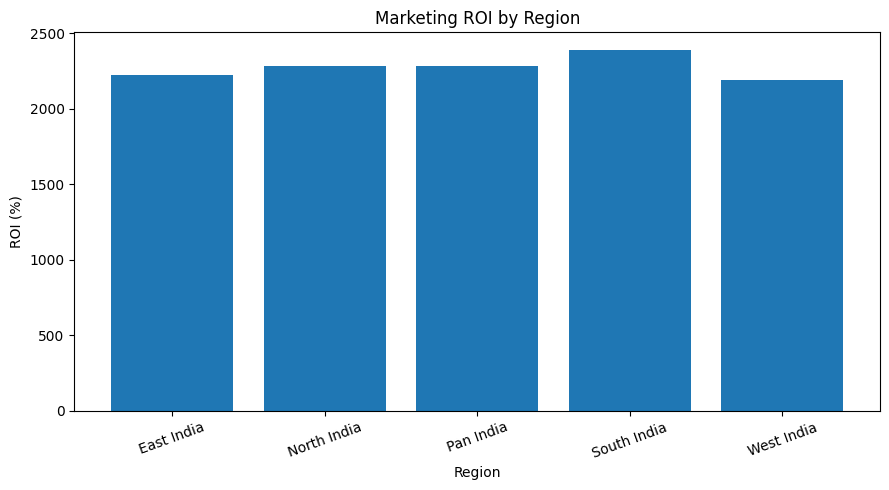

In [14]:
# STEP 9: REGION-WISE ANALYSIS

region_summary = (
    campaign_clean.groupby("Region", as_index=False)
    .agg({
        "Impressions": "sum",
        "Clicks": "sum",
        "Leads": "sum",
        "Enrollments": "sum",
        "Cost (₹)": "sum",
        "Revenue (₹)": "sum"
    })
)

region_summary["ROI (%)"] = (
    (region_summary["Revenue (₹)"] -
     region_summary["Cost (₹)"]) /
    region_summary["Cost (₹)"] * 100
)

region_summary["ROAS"] = (
    region_summary["Revenue (₹)"] /
    region_summary["Cost (₹)"]
)

print("REGION-WISE PERFORMANCE")
display(region_summary.round(2))

# Region ROI chart
plt.figure(figsize=(9, 5))
plt.bar(region_summary["Region"], region_summary["ROI (%)"])
plt.title("Marketing ROI by Region")
plt.xlabel("Region")
plt.ylabel("ROI (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

TARGET AUDIENCE PERFORMANCE


,TargetAudience,Impressions,Clicks,Leads,Enrollments,Cost (₹),Revenue (₹),ROI (%),ROAS
0,17–21 Age,54370348,2996514,593012,163793,38610589.61,9.039015e+08,2241.07,23.41
1,21–35 Age,31329302,1740443,350452,94199,22051324.43,5.172759e+08,2245.78,23.46
2,22–27 Age,22431531,1256544,249869,71590,15662146.55,4.023658e+08,2469.03,25.69
3,25–35 Age,21027008,1144911,227951,62732,15124070.60,3.419193e+08,2160.76,22.61


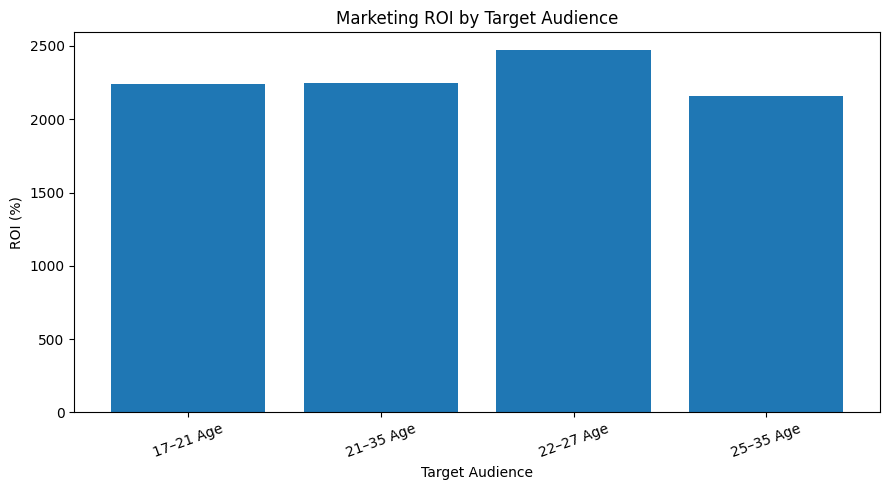

In [15]:
# TARGET AUDIENCE ANALYSIS

audience_summary = (
    campaign_clean.groupby("TargetAudience", as_index=False)
    .agg({
        "Impressions": "sum",
        "Clicks": "sum",
        "Leads": "sum",
        "Enrollments": "sum",
        "Cost (₹)": "sum",
        "Revenue (₹)": "sum"
    })
)

audience_summary["ROI (%)"] = (
    (audience_summary["Revenue (₹)"] -
     audience_summary["Cost (₹)"]) /
    audience_summary["Cost (₹)"] * 100
)

audience_summary["ROAS"] = (
    audience_summary["Revenue (₹)"] /
    audience_summary["Cost (₹)"]
)

print("TARGET AUDIENCE PERFORMANCE")
display(audience_summary.round(2))

# Audience ROI chart
plt.figure(figsize=(9, 5))
plt.bar(
    audience_summary["TargetAudience"],
    audience_summary["ROI (%)"]
)
plt.title("Marketing ROI by Target Audience")
plt.xlabel("Target Audience")
plt.ylabel("ROI (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [16]:
# STEP 10: FINAL BUSINESS INSIGHTS REPORT

# Calculate overall performance
total_spend = campaign_clean["Cost (₹)"].sum()
total_revenue = campaign_clean["Revenue (₹)"].sum()

overall_roi = (
    (total_revenue - total_spend) / total_spend
) * 100

overall_roas = total_revenue / total_spend

# Find best-performing platforms
best_roi = channel_summary.loc[
    channel_summary["ROI (%)"].idxmax()
]

lowest_roi = channel_summary.loc[
    channel_summary["ROI (%)"].idxmin()
]

highest_revenue = channel_summary.loc[
    channel_summary["Revenue (₹)"].idxmax()
]

highest_leads = channel_summary.loc[
    channel_summary["Leads"].idxmax()
]

# Campaign-level best performer
best_campaign = campaign_summary.loc[
    campaign_summary["ROI (%)"].idxmax()
]

# Calculate funnel conversion rates
impressions = campaign_clean["Impressions"].sum()
clicks = campaign_clean["Clicks"].sum()
leads = campaign_clean["Leads"].sum()
applications = campaign_clean["Applications"].sum()
enrollments = campaign_clean["Enrollments"].sum()

# Prepare optional segment findings
region_finding = "Regional analysis not available."
if "region_summary" in globals() and not region_summary.empty:
    r = region_summary.loc[region_summary["ROI (%)"].idxmax()]
    region_finding = f"{r['Region']} recorded the highest regional ROI."

audience_finding = "Audience analysis not available."
if "audience_summary" in globals() and not audience_summary.empty:
    a = audience_summary.loc[
        audience_summary["ROI (%)"].idxmax()
    ]
    audience_finding = (
        f"{a['TargetAudience']} recorded the highest audience ROI."
    )

# Check budget consistency
listed_budget = meta_df["Budget (₹)"].sum()

budget_warning = ""
if listed_budget > 0:
    budget_warning = (
        f"Recorded spending is ₹{total_spend:,.2f}, while listed "
        f"campaign budgets total ₹{listed_budget:,.2f}. "
        "Confirm that the budget and spending periods are comparable "
        "before making final budget allocation decisions."
    )

# Prepare final report
report = f"""
BUSINESS INSIGHTS REPORT
Marketing Campaign Performance Analysis

1. EXECUTIVE SUMMARY

This analysis evaluates marketing campaign performance across
Facebook, Google Ads, Instagram, LinkedIn and YouTube.
The objective is to identify effective advertising channels,
understand the marketing funnel and support better budget decisions.

2. KEY PERFORMANCE FINDINGS

Overall ROI: {overall_roi:.2f}%
Overall ROAS: {overall_roas:.2f}

Highest ROI Platform: {best_roi['Platform']}
ROI: {best_roi['ROI (%)']:.2f}%

Lowest ROI Platform: {lowest_roi['Platform']}
ROI: {lowest_roi['ROI (%)']:.2f}%

Highest Revenue Platform: {highest_revenue['Platform']}
Revenue: ₹{highest_revenue['Revenue (₹)']:,.2f}

Highest Lead Generation Platform: {highest_leads['Platform']}
Leads: {highest_leads['Leads']:,.0f}

Best Campaign: {best_campaign['CampaignName']}
Platform: {best_campaign['Platform']}
ROI: {best_campaign['ROI (%)']:.2f}%

3. MARKETING FUNNEL

Impressions: {impressions:,.0f}
Clicks: {clicks:,.0f}
Leads: {leads:,.0f}
Applications: {applications:,.0f}
Enrollments: {enrollments:,.0f}

Click-through rate: {clicks / impressions * 100:.2f}%
Click-to-lead conversion: {leads / clicks * 100:.2f}%
Lead-to-application conversion: {applications / leads * 100:.2f}%
Application-to-enrollment conversion: {enrollments / applications * 100:.2f}%

4. CUSTOMER SEGMENT INSIGHTS

{region_finding}
{audience_finding}

5. BUSINESS RECOMMENDATIONS

• Consider a controlled increase in LinkedIn investment because
  it recorded the highest ROI and ROAS.

• Retain Google Ads as an important revenue-generating channel
  and continue monitoring its advertising costs.

• Use Facebook's strong lead generation performance while
  monitoring the quality of leads and application conversions.

• Review YouTube advertising creatives, targeting and landing pages
  to improve its comparatively lower ROI.

• Verify campaign budgets against recorded spending before
  approving changes to budget allocation.

6. CONCLUSION

The analysis indicates that LinkedIn delivered the highest ROI,
while Google Ads generated the highest revenue and Facebook
generated the most leads. A measured, data-driven approach to
campaign optimization can help improve marketing effectiveness.

DATA QUALITY NOTE
{budget_warning}
"""

print(report)

# Save the report
with open("Business_Insights_Report.txt", "w", encoding="utf-8") as f:
    f.write(report)

print("\nReport saved successfully!")


BUSINESS INSIGHTS REPORT
Marketing Campaign Performance Analysis

1. EXECUTIVE SUMMARY

This analysis evaluates marketing campaign performance across
Facebook, Google Ads, Instagram, LinkedIn and YouTube.
The objective is to identify effective advertising channels,
understand the marketing funnel and support better budget decisions.

2. KEY PERFORMANCE FINDINGS

Overall ROI: 2267.97%
Overall ROAS: 23.68

Highest ROI Platform: LinkedIn
ROI: 2444.56%

Lowest ROI Platform: YouTube
ROI: 2112.57%

Highest Revenue Platform: Google Ads
Revenue: ₹531,973,533.88

Highest Lead Generation Platform: Facebook
Leads: 350,452

Best Campaign: Placements
Platform: LinkedIn
ROI: 2444.56%

3. MARKETING FUNNEL

Impressions: 129,158,189
Clicks: 7,138,412
Leads: 1,421,284
Applications: 783,616
Enrollments: 392,314

Click-through rate: 5.53%
Click-to-lead conversion: 19.91%
Lead-to-application conversion: 55.13%
Application-to-enrollment conversion: 50.06%

4. CUSTOMER SEGMENT INSIGHTS

South India recorded